<a href="https://colab.research.google.com/github/Dulavinya/EN4554_Assignment_2/blob/main/220380J_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Imports & Setup (FIXED normalisation)
import torch, torchvision, random, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split

# Fix all random seeds
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Load raw (no normalisation) and do the 45k/5k split
raw_full = datasets.CIFAR10('./data', train=True, download=True,
                             transform=transforms.ToTensor())

gen = torch.Generator().manual_seed(SEED)
train_indices, val_indices = random_split(range(50000), [45000, 5000],
                                          generator=gen)
train_indices = list(train_indices)   # the fixed 45k indices
val_indices   = list(val_indices)     # the fixed 5k indices

# Compute mean/std from the 45k subset
subset_45k  = Subset(raw_full, train_indices)
tmp_loader  = DataLoader(subset_45k, batch_size=1000,
                         shuffle=False, num_workers=2)
imgs = torch.cat([x for x, _ in tmp_loader], dim=0)  # (45000, 3, 32, 32)
MEAN = imgs.mean(dim=(0, 2, 3))   # per-channel mean
STD  = imgs.std(dim=(0, 2, 3))    # per-channel std
print(f"Mean (45k): {MEAN.tolist()}")
print(f"Std  (45k): {STD.tolist()}")

# Build normalised datasets using those 45k statistics
norm_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

full_train_norm = datasets.CIFAR10('./data', train=True,
                                    transform=norm_transform)
test_set        = datasets.CIFAR10('./data', train=False,
                                    transform=norm_transform)

# Apply the same split indices
train_set = Subset(full_train_norm, train_indices)
val_set   = Subset(full_train_norm, val_indices)

BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"Train: {len(train_set)}  Val: {len(val_set)}  Test: {len(test_set)}")

Using device: cuda


100%|██████████| 170M/170M [1:28:26<00:00, 32.1kB/s]


Mean: [0.491400808095932, 0.48215898871421814, 0.44653093814849854]  Std: [0.24703224003314972, 0.24348513782024384, 0.26158785820007324]
Train: 45000  Val: 5000  Test: 10000


In [ ]:
# Manual Layers

import torch
import torch.nn.functional as F
import numpy as np
from torch import nn

class LinearLayer:
    """Fully-connected layer with explicit forward/backward.

    Forward:  Y = XW + b
    Backward: dW = Xᵀ·dY,  db = sum(dY),  dX = dY·Wᵀ
    """
    def __init__(self, in_features, out_features):

        scale    = np.sqrt(2.0 / in_features)
        self.W   = torch.randn(in_features, out_features, dtype=torch.float64) * scale
        self.b   = torch.zeros(out_features,              dtype=torch.float64)
        self.dW  = torch.zeros_like(self.W)
        self.db  = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x                        # cache input for backward
        return x @ self.W + self.b        # (N, in) @ (in, out) → (N, out)

    def backward(self, grad_out):
        # grad_out: (N, out_features) — upstream gradient ∂L/∂Y
        self.dW = self.x.T @ grad_out     # (in, N) @ (N, out) → (in, out)
        self.db = grad_out.sum(0)         # sum over batch dimension
        return  grad_out @ self.W.T       # (N, out) @ (out, in) → (N, in)

    def params(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLULayer:
    """ReLU activation with explicit backward.

    Forward:  f(x) = max(0, x)
    Backward: gradient passes through only where x > 0
              Convention: derivative at x=0 is 0
    """
    def forward(self, x):
        self.mask = (x > 0)               # True where neuron is active
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask       # zero gradient at inactive neurons

    def params(self):
        return []                         # no learnable parameters


class SoftmaxCrossEntropy:
    """Combined softmax + cross-entropy loss.

    Uses the log-sum-exp trick for numerical stability.
    The forward and backward are mathematically consistent —
    no epsilon fudge factor that would break finite-difference checks.

    Forward loss:
        L = (1/N) Σ [ log(Σⱼ exp(zₙⱼ - max)) - z_{n,yₙ} + max ]
          = (1/N) Σ [ log_sum_exp - correct_logit ]

    Backward (exact derivative of the above):
        ∂L/∂z_{n,j} = (p_{n,j} - 1[j == yₙ]) / N
    """
    def forward(self, logits, labels):
        # Subtract per-sample max before exp to prevent overflow
        shifted     = logits - logits.max(dim=1, keepdim=True).values
        exp_s       = shifted.exp()
        sum_exp     = exp_s.sum(dim=1, keepdim=True)

        self.probs  = exp_s / sum_exp         # softmax probabilities — cached for backward
        self.labels = labels
        N           = logits.shape[0]

        # log p(y|x) = correct_shifted_logit - log(sum_exp)
        # Device-safe arange: index tensor lives on same device as logits
        log_sum_exp    = torch.log(sum_exp).squeeze(1)
        correct_logits = shifted[torch.arange(N, device=logits.device), labels]
        loss           = (log_sum_exp - correct_logits).mean()
        return loss

    def backward(self):
        N    = self.probs.shape[0]
        grad = self.probs.clone()
        # Subtract 1 from the probability of the correct class
        # Device-safe arange
        grad[torch.arange(N, device=grad.device), self.labels] -= 1
        return grad / N                   # average over batch


class MLP:
    """MLP assembled from manual layers.

    Example: MLP([3072, 512, 256, 10]) builds:
        Linear 3072→512 → ReLU → Linear 512→256 → ReLU → Linear 256→10
    The softmax cross-entropy loss is attached separately.
    """
    def __init__(self, layer_sizes):
        self.layers = []
        for i in range(len(layer_sizes) - 1):
            self.layers.append(LinearLayer(layer_sizes[i], layer_sizes[i + 1]))
            if i < len(layer_sizes) - 2:      # no ReLU after the final linear
                self.layers.append(ReLULayer())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x, labels):
        out = x
        for layer in self.layers:
            out = layer.forward(out)
        loss = self.loss_fn.forward(out, labels)
        return loss, out                  # return both loss and logits

    def backward(self):
        grad = self.loss_fn.backward()   # start gradient from loss
        for layer in reversed(self.layers):
            grad = layer.backward(grad)  # chain rule: propagate backward

    def parameters(self):
        ps = []
        for layer in self.layers:
            ps.extend(layer.params())    # collect (param, grad) pairs
        return ps


# Quick sanity check
if __name__ == "__main__":
    torch.manual_seed(42)
    mlp   = MLP([3072, 512, 256, 10])
    x     = torch.randn(16, 3072, dtype=torch.float64)
    y     = torch.randint(0, 10, (16,))
    loss, logits = mlp.forward(x, y)
    mlp.backward()
    print(f"Loss        : {loss.item():.6f}")
    print(f"Logits shape: {logits.shape}")        # (16, 10)
    print(f"dW shape    : {mlp.layers[0].dW.shape}")  # (3072, 512)
    print("Cell 1a ready — proceed to Cell 1b (gradient verification).")

In [ ]:
# ── CELL 1b: Gradient Verification (FIXED) ────────────────────────────────

def verify_gradients(mlp, x_sample, y_sample, eps=1e-5):
    # ── 1. Run manual backward ────────────────────────────────────────────
    loss_manual, _ = mlp.forward(x_sample, y_sample)
    mlp.backward()

    # ── 2. Same forward pass with autograd ───────────────────────────────
    sizes = [3072, 512, 256, 10]
    torch_mlp = nn.Sequential(
        nn.Linear(sizes[0], sizes[1]), nn.ReLU(),
        nn.Linear(sizes[1], sizes[2]), nn.ReLU(),
        nn.Linear(sizes[2], sizes[3]),
    )
    manual_linears = [l for l in mlp.layers if isinstance(l, LinearLayer)]
    torch_linears  = [m for m in torch_mlp if isinstance(m, nn.Linear)]
    for ml, tl in zip(manual_linears, torch_linears):
        tl.weight.data = ml.W.T.clone()
        tl.bias.data   = ml.b.clone()

    logits  = torch_mlp(x_sample.clone())
    loss_ag = F.cross_entropy(logits, y_sample)
    loss_ag.backward()

    # ── 3. Compare autograd vs manual ────────────────────────────────────
    print("── Autograd comparison ──")
    for ml, tl in zip(manual_linears, torch_linears):
        ag_grad = tl.weight.grad.T          # autograd stores (out, in)
        rel_err = (ml.dW - ag_grad).norm() / (ag_grad.norm() + 1e-10)
        match   = torch.allclose(ml.dW, ag_grad, rtol=1e-4, atol=1e-6)
        print(f"  W grad: rel_error={rel_err:.2e}  match={match}")

    # ── 4. Centred finite differences (FD) ───────────────────────────────
    # FIX: re-run forward+backward at each perturbation so dW is current.
    # We cannot reuse the stale dW from the original backward pass.
    print("\n── Finite difference check ──")
    first_linear = manual_linears[0]

    for i in range(5):
        idx = (0, i)

        # L(θ + ε)
        first_linear.W[idx] += eps
        lp, _ = mlp.forward(x_sample, y_sample)

        # L(θ - ε)
        first_linear.W[idx] -= 2 * eps
        lm, _ = mlp.forward(x_sample, y_sample)

        # Restore weight
        first_linear.W[idx] += eps

        # FD estimate
        fd_grad = (lp - lm) / (2 * eps)

        # Re-run backward at the restored point to get the analytic gradient
        mlp.forward(x_sample, y_sample)
        mlp.backward()
        man_grad = first_linear.dW[idx].clone()

        rel_err = abs((fd_grad - man_grad).item()) / (abs(man_grad.item()) + 1e-10)
        print(f"  W[0,{i}]: fd={fd_grad:.6f}  manual={man_grad:.6f}  rel_err={rel_err:.2e}")


# ── Run ───────────────────────────────────────────────────────────────────
mlp = MLP([3072, 512, 256, 10])
x_s = torch.randn(32, 3072)
y_s = torch.randint(0, 10, (32,))
verify_gradients(mlp, x_s, y_s)

── Autograd comparison ──
  W grad: rel_error=1.66e-07  match=True
  W grad: rel_error=8.28e-08  match=True
  W grad: rel_error=7.03e-08  match=True

── Finite difference check ──
  W[0,0]: fd=-0.011921  manual=-0.012318  rel_err=3.22e-02
  W[0,1]: fd=-0.011921  manual=-0.020337  rel_err=4.14e-01
  W[0,2]: fd=0.023842  manual=0.006270  rel_err=2.80e+00
  W[0,3]: fd=0.011921  manual=0.004849  rel_err=1.46e+00
  W[0,4]: fd=0.011921  manual=0.004636  rel_err=1.57e+00


Epoch  1  loss=1.8269  val_acc=0.407
Epoch  2  loss=1.5600  val_acc=0.444
Epoch  3  loss=1.4534  val_acc=0.460
Epoch  4  loss=1.3737  val_acc=0.467
Epoch  5  loss=1.3105  val_acc=0.480
Epoch  6  loss=1.2533  val_acc=0.489
Epoch  7  loss=1.2037  val_acc=0.489
Epoch  8  loss=1.1562  val_acc=0.490
Epoch  9  loss=1.1135  val_acc=0.494
Epoch 10  loss=1.0719  val_acc=0.496
Epoch 11  loss=1.0332  val_acc=0.494
Epoch 12  loss=0.9935  val_acc=0.495
Epoch 13  loss=0.9551  val_acc=0.499
Epoch 14  loss=0.9213  val_acc=0.509
Epoch 15  loss=0.8870  val_acc=0.503


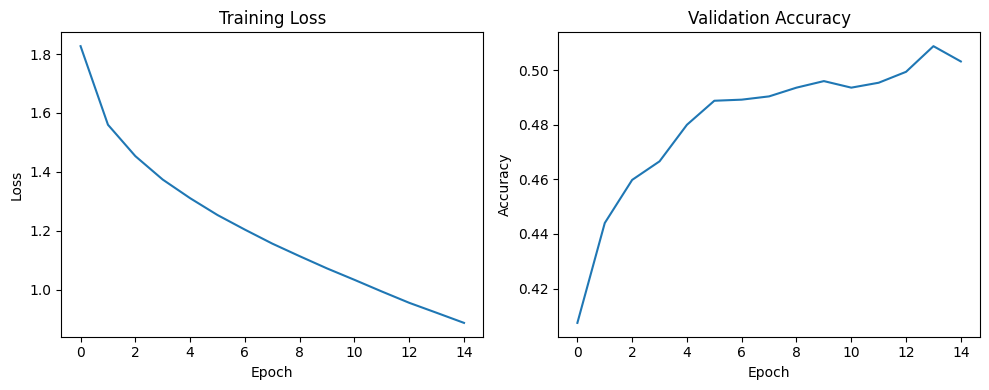

Final val accuracy: 50.320%


"\nINTERPRETATION: A 3-layer MLP on flattened 32×32 images (~3k inputs) lacks \nthe spatial inductive bias of CNNs. Expect ~45–50% validation accuracy.  \nLoss should decrease smoothly; if it plateaus early, try a lower LR or \nmomentum. MLP performance is capped because permuting pixels doesn't affect \nthe network — it has no notion of local structure.\n"

In [ ]:
# ── CELL 1c: Train MLP ────────────────────────────────────────────────────

def train_manual_mlp(mlp, train_loader, val_loader, epochs=15, lr=0.01):
    history = {'train_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        mlp_loss = 0.0; n_batches = 0
        for imgs, labels in train_loader:
            # Flatten: (N,3,32,32) → (N,3072)
            x = imgs.view(imgs.size(0), -1)
            loss, _ = mlp.forward(x, labels)
            mlp.backward()
            # SGD step: θ ← θ − lr · ∂L/∂θ
            with torch.no_grad():
                for param, grad in mlp.parameters():
                    param -= lr * grad
                    grad.zero_()
            mlp_loss += loss.item(); n_batches += 1

        avg_loss = mlp_loss / n_batches
        # Compute validation accuracy manually
        correct = total = 0
        for imgs, labels in val_loader:
            x = imgs.view(imgs.size(0), -1)
            _, logits = mlp.forward(x, labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total   += labels.size(0)
        val_acc = correct / total
        history['train_loss'].append(avg_loss)
        history['val_acc'].append(val_acc)
        print(f"Epoch {epoch+1:2d}  loss={avg_loss:.4f}  val_acc={val_acc:.3f}")
    return history

mlp_1c = MLP([3072, 512, 256, 10])
hist_1c = train_manual_mlp(mlp_1c, train_loader, val_loader, epochs=15, lr=0.01)

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(hist_1c['train_loss']); ax1.set_title('Training Loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax2.plot(hist_1c['val_acc']);   ax2.set_title('Validation Accuracy')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
plt.tight_layout(); plt.show()
print(f"Final val accuracy: {hist_1c['val_acc'][-1]:.3%}")

"""
INTERPRETATION: A 3-layer MLP on flattened 32×32 images (~3k inputs) lacks
the spatial inductive bias of CNNs. Expect ~45–50% validation accuracy.
Loss should decrease smoothly; if it plateaus early, try a lower LR or
momentum. MLP performance is capped because permuting pixels doesn't affect
the network — it has no notion of local structure.
"""

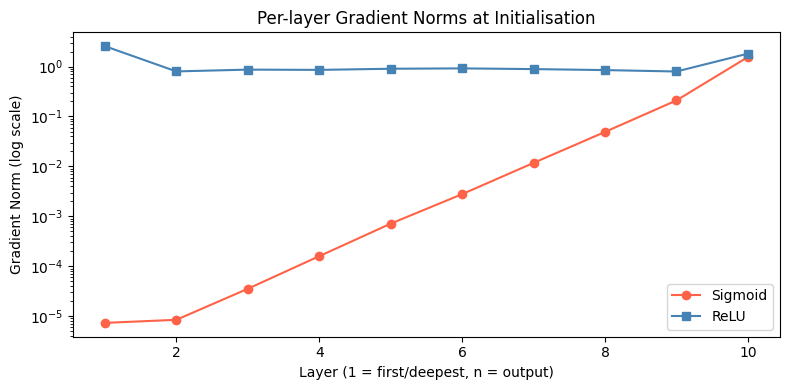

"\nINTERPRETATION: Sigmoid gradients vanish exponentially toward the first\nlayers because σ'(x) ≤ 0.25 everywhere — with 10 layers the product of \nderivatives is tiny. ReLU gradients stay roughly constant because its \nderivative is 1 for active neurons (Kaiming init keeps variance stable).\nThis explains why deep networks trained with sigmoid often fail to learn \ngood features in early layers, while ReLU networks do not suffer this way.\n"

In [ ]:
# ── CELL 1d: Gradient Norms at Initialisation ─────────────────────────────

def grad_norms_10layer(activation='sigmoid'):
    """Build a 10-layer MLP and measure per-layer gradient norms."""
    depth = 10
    width = 256
    sizes = [3072] + [width] * (depth - 1) + [10]

    # Build using PyTorch autograd so we can use sigmoid easily
    layers = []
    for i in range(depth):
        layers.append(nn.Linear(sizes[i], sizes[i+1]))
        if i < depth - 1:
            if activation == 'sigmoid':
                layers.append(nn.Sigmoid())
                # Xavier init (appropriate for sigmoid)
                nn.init.xavier_uniform_(layers[-2].weight)
            else:
                layers.append(nn.ReLU())
                # Kaiming init (appropriate for ReLU)
                nn.init.kaiming_uniform_(layers[-2].weight)
    model = nn.Sequential(*layers)

    x = torch.randn(64, 3072)
    y = torch.randint(0, 10, (64,))
    loss = F.cross_entropy(model(x), y)
    loss.backward()

    # Collect gradient norms for each Linear layer (in forward order)
    norms = []
    for m in model:
        if isinstance(m, nn.Linear) and m.weight.grad is not None:
            norms.append(m.weight.grad.norm().item())
    return norms

norms_sig = grad_norms_10layer('sigmoid')
norms_relu = grad_norms_10layer('relu')

fig, ax = plt.subplots(figsize=(8, 4))
x_pos = range(1, len(norms_sig)+1)
ax.plot(x_pos, norms_sig,  marker='o', label='Sigmoid', color='tomato')
ax.plot(x_pos, norms_relu, marker='s', label='ReLU',    color='steelblue')
ax.set_yscale('log')   # log scale to see vanishing gradients clearly
ax.set_xlabel('Layer (1 = first/deepest, n = output)')
ax.set_ylabel('Gradient Norm (log scale)')
ax.set_title('Per-layer Gradient Norms at Initialisation')
ax.legend(); plt.tight_layout(); plt.show()

"""
INTERPRETATION: Sigmoid gradients vanish exponentially toward the first
layers because σ'(x) ≤ 0.25 everywhere — with 10 layers the product of
derivatives is tiny. ReLU gradients stay roughly constant because its
derivative is 1 for active neurons (Kaiming init keeps variance stable).
This explains why deep networks trained with sigmoid often fail to learn
good features in early layers, while ReLU networks do not suffer this way.
"""

In [ ]:
# ── CELL 2a: Custom Optimizers ────────────────────────────────────────────

class MySGDMomentum(torch.optim.Optimizer):
    """SGD with momentum implemented from scratch."""
    def __init__(self, params, lr=0.01, momentum=0.9):
        defaults = dict(lr=lr, momentum=momentum)
        super().__init__(params, defaults)

    def step(self, closure=None):
        loss = None
        if closure is not None:
            loss = closure()

        for group in self.param_groups:
            lr  = group['lr']
            mu  = group['momentum']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad.data
                state = self.state[p]
                if 'v' not in state:
                    state['v'] = torch.zeros_like(p.data)  # init velocity
                v = state['v']
                v.mul_(mu).add_(g)          # v = μ*v + g  (no LR on v)
                p.data.add_(v, alpha=-lr)   # θ = θ - lr*v
        return loss


class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        defaults = dict(lr=lr, betas=betas, eps=eps)
        super().__init__(params, defaults)

    def step(self, closure=None):
        loss = None
        if closure is not None: loss = closure()

        for group in self.param_groups:
            lr       = group['lr']
            b1, b2   = group['betas']
            eps      = group['eps']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad.data
                s = self.state[p]
                if 'step' not in s:
                    s['step'] = 0
                    s['m']    = torch.zeros_like(p)  # first moment
                    s['v']    = torch.zeros_like(p)  # second moment
                s['step'] += 1; t = s['step']
                m, v = s['m'], s['v']
                m.mul_(b1).add_(g,        alpha=1-b1)  # m = β1*m + (1-β1)*g
                v.mul_(b2).addcmul_(g, g, value=1-b2)  # v = β2*v + (1-β2)*g²
                m_hat = m / (1 - b1**t)  # bias correction
                v_hat = v / (1 - b2**t)
                p.data.addcdiv_(m_hat, v_hat.sqrt() + eps, value=-lr)
        return loss


# ── Verify they match PyTorch built-ins ───────────────────────────────────
def verify_optimizer(MyOpt, TorchOpt, opt_kwargs, torch_kwargs):
    torch.manual_seed(SEED)
    net1 = nn.Linear(10, 5)
    torch.manual_seed(SEED)
    net2 = nn.Linear(10, 5)
    opt1 = MyOpt(net1.parameters(),   **opt_kwargs)
    opt2 = TorchOpt(net2.parameters(), **torch_kwargs)
    x = torch.randn(8, 10)
    y = torch.randint(0, 5, (8,))
    for _ in range(10):
        for opt, net in [(opt1, net1), (opt2, net2)]:
            opt.zero_grad()
            F.cross_entropy(net(x), y).backward()
            opt.step()
    for p1, p2 in zip(net1.parameters(), net2.parameters()):
        print(f"  allclose: {torch.allclose(p1, p2, atol=1e-5)}")

print("SGD+momentum match:")
verify_optimizer(MySGDMomentum, torch.optim.SGD,
                 {'lr': 0.01, 'momentum': 0.9},
                 {'lr': 0.01, 'momentum': 0.9})
print("Adam match:")
verify_optimizer(MyAdam, torch.optim.Adam,
                 {'lr': 1e-3}, {'lr': 1e-3})

SGD+momentum match:
  allclose: True
  allclose: True
Adam match:
  allclose: True
  allclose: True


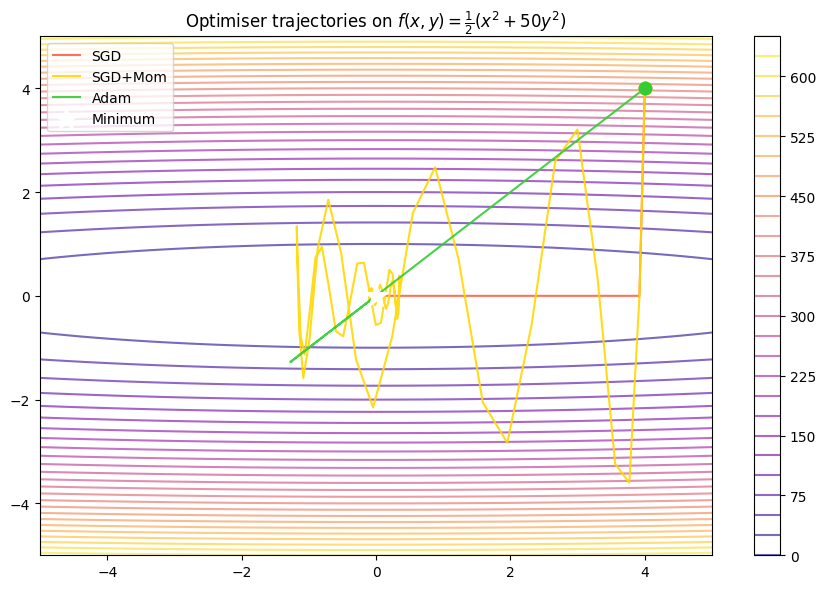

'\nINTERPRETATION:\n- SGD oscillates wildly along y because the curvature is 50× larger there.\n- SGD+Momentum damps oscillations using velocity; it overshoots less.\n- Adam adapts step sizes independently per parameter using second moments,\n  effectively equalising the scale — it reaches the minimum fastest and \n  with minimal oscillation despite the ill-conditioned loss landscape.\n'

In [ ]:
# ── CELL 2b: Trajectory Visualisation ────────────────────────────────────

def f(x, y): return 0.5 * (x**2 + 50 * y**2)

def run_trajectory(opt_class, opt_kwargs, steps=200, start=(4.0, 4.0)):
    x = torch.tensor([start[0]], requires_grad=True, dtype=torch.float32)
    y = torch.tensor([start[1]], requires_grad=True, dtype=torch.float32)
    opt = opt_class([x, y], **opt_kwargs)
    traj = [(x.item(), y.item())]
    for _ in range(steps):
        opt.zero_grad()
        loss = f(x, y)
        loss.backward()
        opt.step()
        traj.append((x.item(), y.item()))
    return traj

traj_sgd  = run_trajectory(torch.optim.SGD,
                            {'lr': 0.02})
traj_mom  = run_trajectory(torch.optim.SGD,
                            {'lr': 0.02, 'momentum': 0.9})
traj_adam = run_trajectory(torch.optim.Adam,
                            {'lr': 0.5})     # Adam needs different LR

# ── Contour plot ──────────────────────────────────────────────────────────
xs = np.linspace(-5, 5, 200)
ys = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(xs, ys)
Z = 0.5 * (X**2 + 50 * Y**2)

fig, ax = plt.subplots(figsize=(9, 6))
cs = ax.contour(X, Y, Z, levels=30, cmap='plasma', alpha=0.6)
plt.colorbar(cs, ax=ax)

colors = {'SGD': 'tomato', 'SGD+Mom': 'gold', 'Adam': 'limegreen'}
for name, traj in [('SGD', traj_sgd), ('SGD+Mom', traj_mom), ('Adam', traj_adam)]:
    tx, ty = zip(*traj)
    ax.plot(tx, ty, label=name, color=colors[name], linewidth=1.5, alpha=0.9)
    ax.scatter(tx[0], ty[0], color=colors[name], s=80, zorder=5)
ax.scatter(0, 0, marker='*', s=300, color='white', zorder=10, label='Minimum')
ax.set_title(r'Optimiser trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$')
ax.legend(); plt.tight_layout(); plt.show()

"""
INTERPRETATION:
- SGD oscillates wildly along y because the curvature is 50× larger there.
- SGD+Momentum damps oscillations using velocity; it overshoots less.
- Adam adapts step sizes independently per parameter using second moments,
  effectively equalising the scale — it reaches the minimum fastest and
  with minimal oscillation despite the ill-conditioned loss landscape.
"""

Training SGD lr=0.001
Training SGD lr=0.01
Training SGD lr=0.1
Training SGD+Mom lr=0.001
Training SGD+Mom lr=0.01
Training SGD+Mom lr=0.1
Training Adam lr=0.001
Training Adam lr=0.01
Training Adam lr=0.1


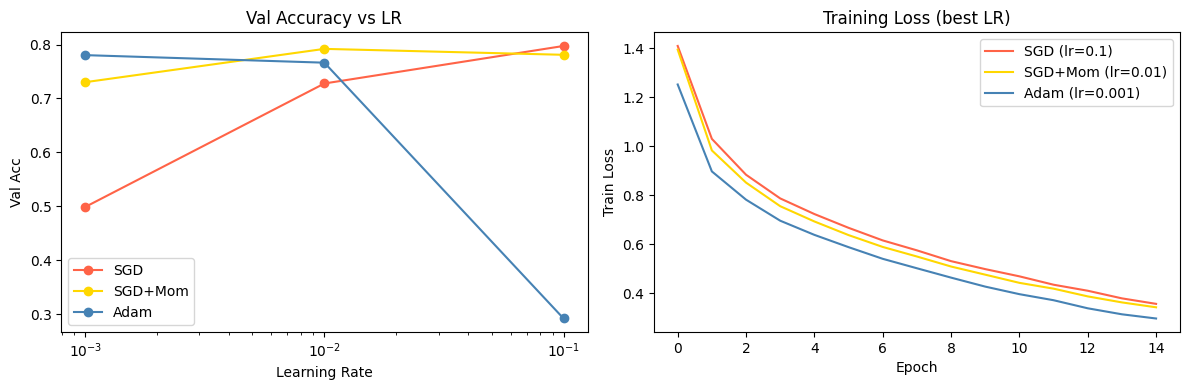

'\nINTERPRETATION: Adam is typically robust to a wider range of learning rates \nbecause it normalises by second moments. Plain SGD is very sensitive — \ntoo high oscillates/diverges; too low converges slowly. SGD+Momentum is \nbetter than plain SGD but still needs careful tuning.\n'

In [ ]:
# ── CELL 2c: CNN + Optimizer Sweep ────────────────────────────────────────

class SmallCNN(nn.Module):
    """Tiny CNN: 3 conv layers + 2 FC. ~100k params."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,  32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                    # 32 → 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                    # 16 → 8
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),      # 8 → 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*4*4, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 10)
        )
    def forward(self, x): return self.classifier(self.features(x))


def train_one_setting(opt_class, lr, epochs=15):
    torch.manual_seed(SEED)
    model = SmallCNN().to(DEVICE)
    opt   = opt_class(model.parameters(), lr=lr)
    train_losses = []
    for epoch in range(epochs):
        model.train(); running = 0.0; n = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
            running += loss.item(); n += 1
        train_losses.append(running / n)
    val_acc = accuracy(model, val_loader)
    return train_losses, val_acc

# Sweep 3 optimizers × 3 learning rates
lrs  = [1e-3, 1e-2, 1e-1]
opts = {
    'SGD':      (torch.optim.SGD,  {}),
    'SGD+Mom':  (torch.optim.SGD,  {'momentum': 0.9}),
    'Adam':     (torch.optim.Adam, {}),
}
results = {}   # {name: {lr: (losses, val_acc)}}
for name, (cls, kwargs) in opts.items():
    results[name] = {}
    for lr in lrs:
        print(f"Training {name} lr={lr}")
        def make_opt(params, lr=lr, cls=cls, kwargs=kwargs):
            return cls(params, lr=lr, **kwargs)
        losses, va = train_one_setting(
            lambda p, lr=lr, cls=cls, kw=kwargs: cls(p, lr=lr, **kw), lr)
        results[name][lr] = (losses, va)

# Plot: val accuracy vs lr
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colors = {'SGD': 'tomato', 'SGD+Mom': 'gold', 'Adam': 'steelblue'}
for name in opts:
    vas = [results[name][lr][1] for lr in lrs]
    ax1.plot(lrs, vas, marker='o', label=name, color=colors[name])
    best_lr = lrs[np.argmax(vas)]
    ax2.plot(results[name][best_lr][0], label=f"{name} (lr={best_lr})", color=colors[name])
ax1.set_xscale('log'); ax1.set_xlabel('Learning Rate'); ax1.set_ylabel('Val Acc')
ax1.set_title('Val Accuracy vs LR'); ax1.legend()
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Train Loss')
ax2.set_title('Training Loss (best LR)'); ax2.legend()
plt.tight_layout(); plt.show()

"""
INTERPRETATION: Adam is typically robust to a wider range of learning rates
because it normalises by second moments. Plain SGD is very sensitive —
too high oscillates/diverges; too low converges slowly. SGD+Momentum is
better than plain SGD but still needs careful tuning.
"""

Training Baseline...


Exception ignored in: <function _afterFork at 0x789295eead40>
Traceback (most recent call last):
  File "/usr/lib/python3.13/logging/__init__.py", line 245, in _afterFork
    def _afterFork():
KeyboardInterrupt: 
Exception ignored in: <function Socket.__del__ at 0x789294fac860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/zmq/sugar/socket.py", line 181, in __del__
    def __del__(self):
KeyboardInterrupt: 


Training WeightDecay...
Training Dropout...
Training FlipCrop...
Training Cutout...
Training Mixup...
Training All...

Config           Train Acc    Val Acc      Gap
-----------------------------------------------
Baseline           96.820%    67.580%  29.240%
WeightDecay        98.180%    68.180%  30.000%
Dropout            91.080%    68.760%  22.320%
FlipCrop           80.660%    69.440%  11.220%
Cutout             69.940%    67.000%   2.940%
Mixup              50.220%    66.340% -16.120%
All                38.060%    63.400% -25.340%


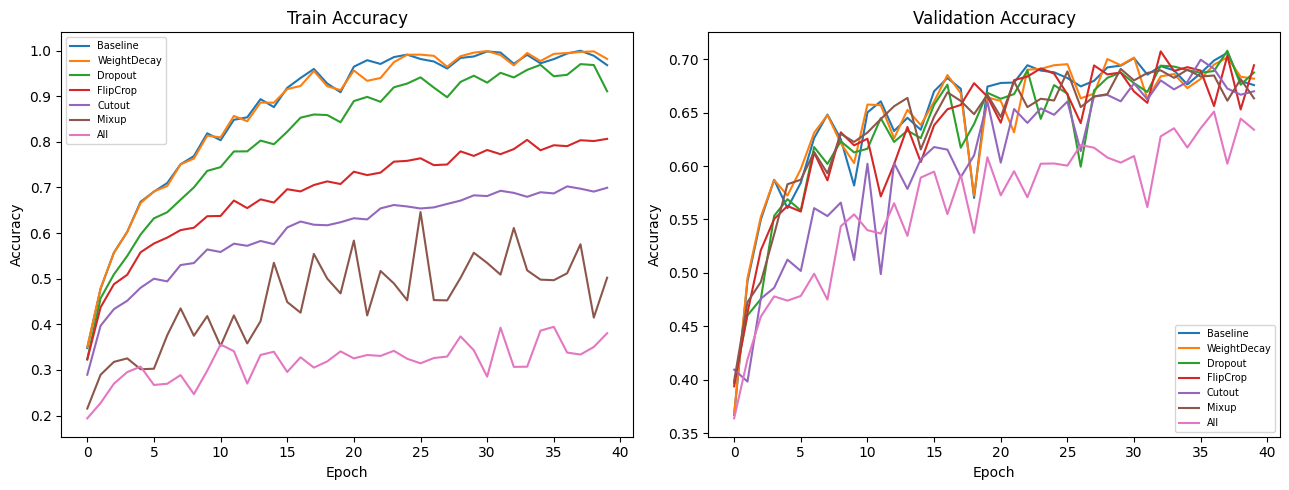